In [ ]:
!pip install yfinance

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


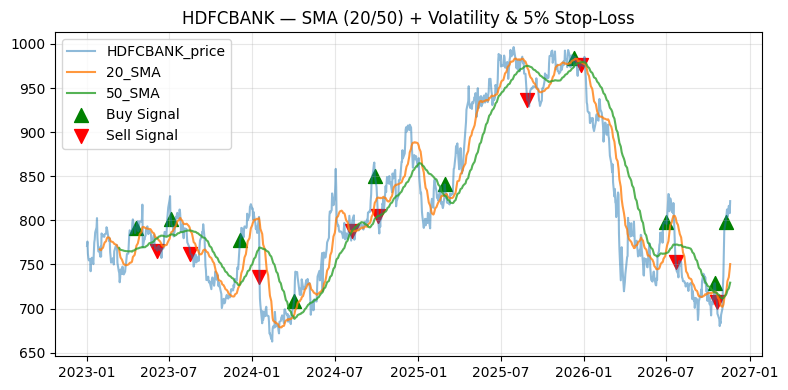

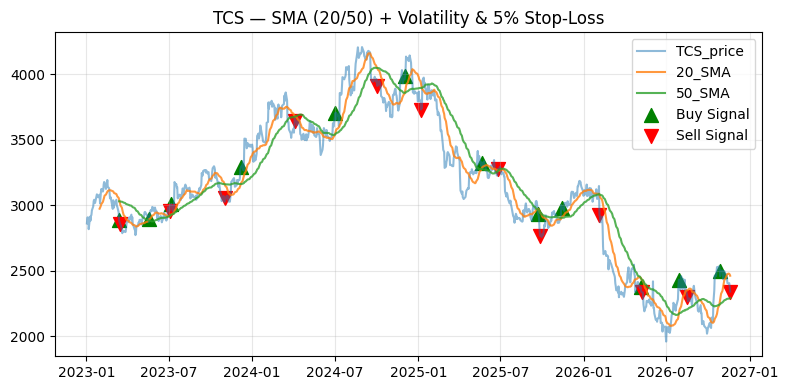

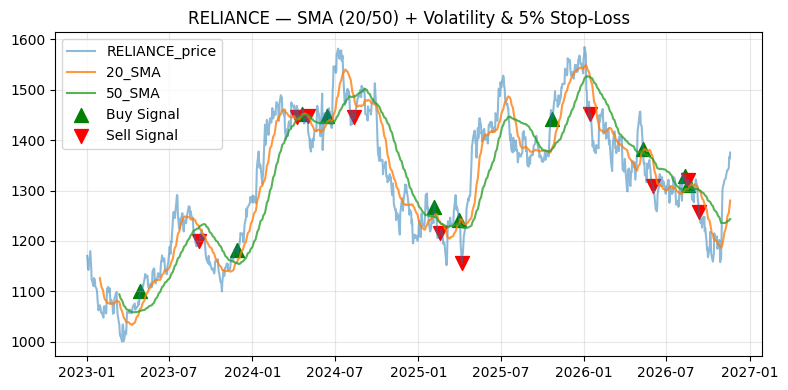

,Close,High,Low,Open,Volume,SMA_20,SMA_50,Volatility,Signal,Position,Statergy_returns,Cummulative_statergy_returns,Cummulative_buy_&_hold
Date,,,,,,,,,,,,,
2023-03-14,1034.181885,1047.359288,1031.046577,1036.022132,16027522,1078.578558,1093.906252,0.014948,0.0,0.0,-0.0,1.000000,0.883555
2023-03-15,1016.505798,1044.337514,1012.120863,1037.885169,21728555,1075.373929,1090.826813,0.014188,0.0,0.0,-0.0,1.000000,0.868454
2023-03-16,1011.439270,1024.207783,1000.670138,1019.209511,18363159,1070.692517,1087.817349,0.012846,0.0,0.0,-0.0,1.000000,0.864125
2023-03-17,1010.167114,1023.276370,1005.441376,1020.004765,34014213,1065.990662,1085.132327,0.012839,0.0,0.0,-0.0,1.000000,0.863038
2023-03-20,1000.238464,1008.758398,990.582543,1006.486424,19524589,1060.561771,1082.289625,0.012730,0.0,0.0,-0.0,1.000000,0.854556
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-11-13,1339.699951,1350.699951,1324.000000,1336.599976,13756247,1249.575000,1239.490000,0.028625,0.0,0.0,0.0,1.079056,1.144575
2026-11-16,1344.800049,1347.300049,1333.800049,1339.699951,7653528,1256.065002,1240.206001,0.027890,0.0,0.0,0.0,1.079056,1.148933
2026-11-17,1367.000000,1374.000000,1335.000000,1339.000000,15905595,1263.855005,1241.284001,0.027918,0.0,0.0,0.0,1.079056,1.167899


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import date
import yfinance as yf


import warnings
warnings.filterwarnings('ignore')

def data(Ticker , start , end) :
  x = yf.download(Ticker , start , end, multi_level_index = False)
  x = x.ffill()
  return x

df1 = data('HDFCBANK.NS' , '2023-01-01' , date.today())
df2 = data('TCS.NS' , '2023-01-01' , date.today())
df3 = data('RELIANCE.NS' , '2023-01-01' , date.today())

def SMA_crossover(df, Ticker, win_sz1, win_sz2, vol_window=20, min_vol=0.008, max_vol=0.025, sl_pct=0.05):
    df[f'SMA_{win_sz1}'] = df['Close'].rolling(window=win_sz1).mean()
    df[f'SMA_{win_sz2}'] = df['Close'].rolling(window=win_sz2).mean()

    df['Volatility'] = df['Close'].pct_change().rolling(window=vol_window).std()
    vol_ok = ((df['Volatility'] >= min_vol) & (df['Volatility'] <= max_vol)).to_numpy()
    trend_up = (df[f'SMA_{win_sz1}'] > df[f'SMA_{win_sz2}']).to_numpy()
    close = df['Close'].to_numpy()

    # State loop: entry gated by volatility, exit on trend break OR stop-loss
    signal = np.zeros(len(df))
    in_trade = False
    entry_price = 0.0
    stopped_out = False

    for i in range(len(df)):
        if not trend_up[i]:
            stopped_out = False  # Reset cooldown once the uptrend ends

        if in_trade:
            stop_hit = close[i] <= entry_price * (1 - sl_pct)
            if (not trend_up[i]) or stop_hit:
                in_trade = False
                signal[i] = 0
                if stop_hit and trend_up[i]:
                    stopped_out = True  # Block immediate re-entry until trend resets
            else:
                signal[i] = 1
        else:
            if trend_up[i] and vol_ok[i] and not stopped_out:
                in_trade = True
                entry_price = close[i]
                signal[i] = 1

    df['Signal'] = signal
    df['Position'] = df['Signal'].diff().fillna(0)

    df['Statergy_returns'] = df['Signal'].shift(1) * df['Close'].pct_change()
    df['Cummulative_statergy_returns'] = (1 + df['Statergy_returns']).cumprod()
    df['Cummulative_buy_&_hold'] = (1 + df['Close'].pct_change()).cumprod()

    plt.figure(figsize=(8, 4))
    plt.plot(df.index, df['Close'], label=f'{Ticker}_price', alpha=0.5)
    plt.plot(df.index, df[f'SMA_{win_sz1}'], label=f'{win_sz1}_SMA', alpha=0.8)
    plt.plot(df.index, df[f'SMA_{win_sz2}'], label=f'{win_sz2}_SMA', alpha=0.8)

    buy_signals = df[df['Position'] == 1].index
    sell_signals = df[df['Position'] == -1].index

    plt.scatter(buy_signals, df.loc[buy_signals, 'Close'], marker='^', s=100, color='green', label='Buy Signal')
    plt.scatter(sell_signals, df.loc[sell_signals, 'Close'], marker='v', s=100, color='red', label='Sell Signal')

    plt.title(f'{Ticker} — SMA ({win_sz1}/{win_sz2}) + Volatility & {sl_pct:.0%} Stop-Loss')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    return df.dropna(subset=[f'SMA_{win_sz2}']).copy()

SMA_crossover(df1 , 'HDFCBANK' , 20 , 50)
SMA_crossover(df2 , 'TCS' , 20 , 50)
SMA_crossover(df3 , 'RELIANCE' , 20 , 50)


In [ ]:
#backtesting

#fixed position sizing

def port_comp(df1 , Ticker) :

    initial_capital = 50000
    fixed_shares = 12
    cost_per_share = 0.0015

    daily_pnl = df1['Close'].diff() * fixed_shares * df1['Signal'].shift(1)
    daily_fees = (fixed_shares * (cost_per_share) * df1['Close'].shift(1) * df1['Position'].shift(1)).abs()

    df1['Fixed_portfolio'] = initial_capital + (daily_pnl - daily_fees).cumsum()

    #percent position sizing
    alloc = 0.5 #50% of capital
    fee_pct = 0.0015

    pct_ret = alloc * (( df1['Close'].pct_change() * df1['Signal'].shift(1)) - (fee_pct * df1['Position'].shift(1)).abs())

    df1['Pc_portfolio'] = initial_capital * (1 + pct_ret).cumprod()

    print (Ticker , df1[['Fixed_portfolio' , 'Pc_portfolio']] , sep = '\n')

port_comp(df1 , 'HDFC')
port_comp(df2 , 'TCS')
port_comp(df3 , 'RELIANCE')



HDFC
            Fixed_portfolio  Pc_portfolio
Date                                     
2023-01-02              NaN           NaN
2023-01-03     50000.000000  50000.000000
2023-01-04     50000.000000  50000.000000
2023-01-05     50000.000000  50000.000000
2023-01-06     50000.000000  50000.000000
...                     ...           ...
2026-11-13     49162.547740  47964.129353
2026-11-16     49312.547740  48336.984836
2026-11-17     49293.947886  48291.105022
2026-11-18     49212.348033  48089.633202
2026-11-19     49376.147593  48495.759362

[958 rows x 2 columns]
TCS
            Fixed_portfolio  Pc_portfolio
Date                                     
2023-01-02              NaN           NaN
2023-01-03     50000.000000  50000.000000
2023-01-04     50000.000000  50000.000000
2023-01-05     50000.000000  50000.000000
2023-01-06     50000.000000  50000.000000
...                     ...           ...
2026-11-13     46971.950896  47541.979578
2026-11-16     46941.950896  47517.295269
2

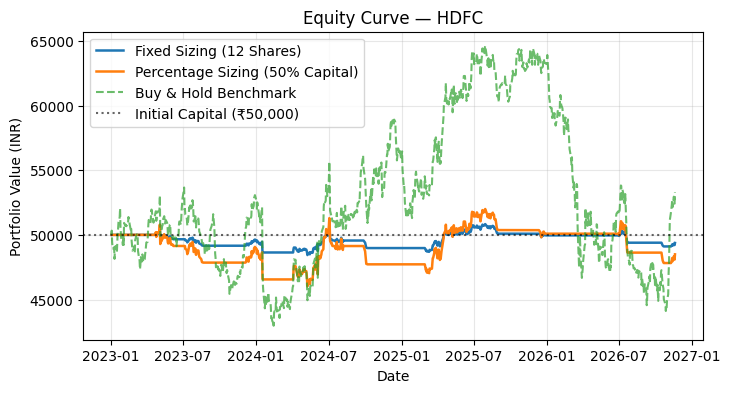

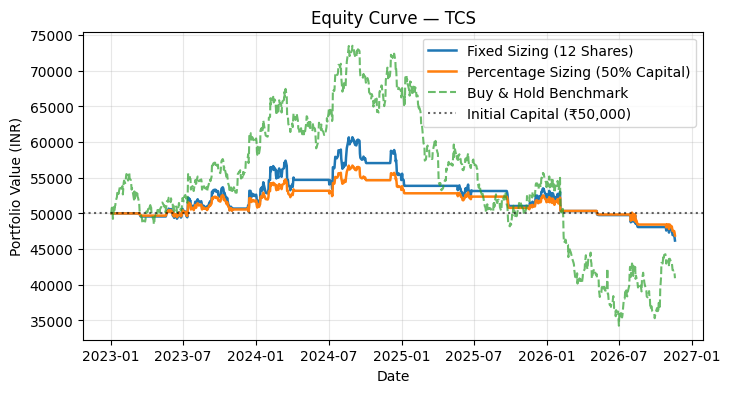

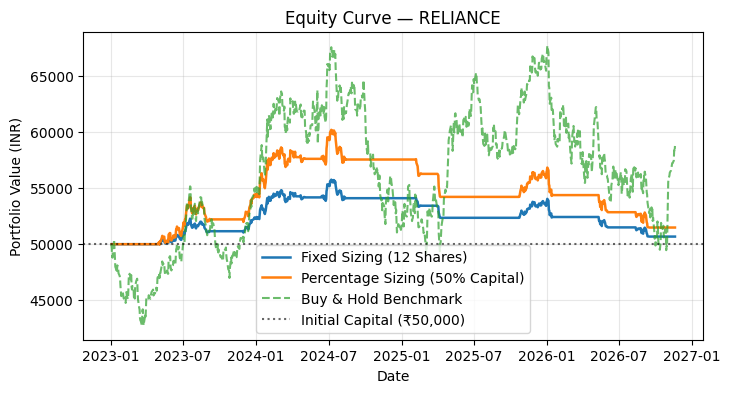

In [ ]:
def plot_equity_curve(df, Ticker, initial_capital=50000):
    # Buy & Hold benchmark scaled to the same ₹50,000 starting capital
    buy_hold = initial_capital * (1 + df['Close'].pct_change().fillna(0)).cumprod()

    plt.figure(figsize=(8, 4))

    plt.plot(df.index, df['Fixed_portfolio'], label='Fixed Sizing (12 Shares)', linewidth=1.8)
    plt.plot(df.index, df['Pc_portfolio'], label='Percentage Sizing (50% Capital)', linewidth=1.8)
    plt.plot(df.index, buy_hold, label='Buy & Hold Benchmark', linestyle='--', alpha=0.7)

    plt.axhline(initial_capital, color='black', linestyle=':', alpha=0.6, label=f'Initial Capital (₹{initial_capital:,})')

    plt.title(f'Equity Curve — {Ticker}')
    plt.xlabel('Date')
    plt.ylabel('Portfolio Value (INR)')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

plot_equity_curve(df1, 'HDFC')
plot_equity_curve(df2, 'TCS')
plot_equity_curve(df3, 'RELIANCE')

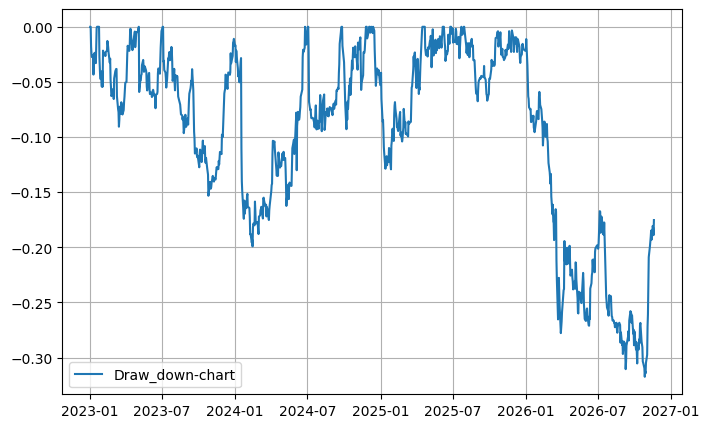

In [ ]:
df1['draw_down'] = (df1['Close'] - df1['Close'].cummax()) / df1['Close'].cummax()

plt.figure(figsize = (8,5))

plt.plot(df1.index , df1['draw_down'] , label = 'Draw_down-chart')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
df1['Last_buy'] = np.where(df1['Position'] == 1 , df1['Close'] , np.nan)
df1['Last_buy'] = df1['Last_buy'].ffill().fillna(0)

# df1.loc[ '2023-04-20' : '2023-04-25' , ['Position' , 'Last_buy']]
total_trades = df1[df1['Position'] == -1].shape[0]
profit_trades = df1[['Close' , 'Last_buy' , 'Position']][ (df1['Last_buy'] < df1['Close'] ) & (df1['Position'] == -1)].shape[0]
win_rate = profit_trades / total_trades
win_loss_ratio = profit_trades / (total_trades - profit_trades)

print(f"total_trades : {total_trades:.2f}\nprofit_trades : {profit_trades:.2f}\nwin_rate : {win_rate:.2f}" , sep = "")


total_trades : 9.00
profit_trades : 2.00
win_rate : 0.22


In [ ]:
strat_dd = (df1['Cummulative_statergy_returns'] / df1['Cummulative_statergy_returns'].cummax()) - 1

total_return  = df1['Cummulative_statergy_returns'].iloc[-1] - 1
annual_return = ((df1['Cummulative_statergy_returns'].iloc[-1]) ** (252/df1.shape[0])) - 1
max_draw_down = strat_dd.min()
calmar_ratio = annual_return / abs(max_draw_down)
sharpe_ratio =  (np.sqrt(252) * (df1['Statergy_returns'].mean() - 0.0005)) / df1['Statergy_returns'].std()

print(f"Total Return  : {total_return:.2%}")
print(f"Annual Return : {annual_return:.2%}")
print(f"Max Drawdown  : {max_draw_down:.2%}")
print(f"Calmar Ratio  : {calmar_ratio:.2f}")
print(f"Sharpe Ratio  : {sharpe_ratio:.2f}")

Total Return  : -4.65%
Annual Return : -1.25%
Max Drawdown  : -17.57%
Calmar Ratio  : -0.07
Sharpe Ratio  : -1.04
